# Análise Exploratória de Dados — Desafio Gerdau

## 1. Introdução

Neste notebook, vou apresentar a análise exploratória da base de dados disponibilizada pela Gerdau para o desafio do Geração Caldeira.

O objetivo dessa análise é conhecer melhor os dados e identificar possíveis problemas no cadastro dos serviços, como códigos repetidos, descrições iguais com códigos diferentes e diferenças na forma como os serviços foram escritos.

Também vou analisar a base que passou pelo processo de normalização textual e agrupamento por similaridade, para entender o que mudou e quais pontos precisam de atenção.

A ideia não é sair alterando ou excluindo registros, mas encontrar situações que possam ser investigadas e ajudar a equipe a definir critérios para a padronização dos dados.

## 2. Objetivos da análise

O principal objetivo é entender como os serviços estão cadastrados na base da Gerdau e identificar possíveis inconsistências que possam dificultar a organização e a padronização dos dados.

Durante a análise, vou procurar entender quantos registros e códigos existem, quais serviços aparecem com mais frequência e se existem códigos ou descrições que se repetem.

Também quero comparar a base original com a base tratada, para verificar os resultados da normalização textual e identificar situações em que serviços diferentes podem ter sido agrupados por apresentarem descrições parecidas.

Com isso, espero reunir informações que ajudem a equipe a identificar quais registros precisam de revisão e quais cuidados devem ser considerados na padronização.


### 2.1 Importação das bibliotecas

Para começar a análise dos dados, vou utilizar duas bibliotecas do Python: **Pandas** e **Matplotlib**.

O **Pandas** vai me ajudar a carregar a planilha Excel, organizar as informações e analisar os registros, como contar códigos e identificar possíveis repetições.

Já o **Matplotlib** será utilizado para criar gráficos, facilitando a visualização dos resultados e a comparação das informações encontradas.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


### 2.2 Carregamento da base de dados

Nesta etapa, vou carregar a planilha Excel disponibilizada pela Gerdau para começar a trabalhar com os dados.

Primeiro, vou verificar quais abas estão disponíveis no arquivo e identificar qual delas contém a base principal de serviços que será analisada.

Vou utilizar os dados originais, sem realizar alterações, para entender como as informações estão organizadas e depois conseguir comparar com a base que passou pelo processo de padronização realizado pela equipe.

In [ ]:
from google.colab import files

arquivos = files.upload()

nome_arquivo = next(iter(arquivos))

excel = pd.ExcelFile(nome_arquivo)

print("Abas disponíveis:")
print(excel.sheet_names)

Saving base_gerdau.xlsx to base_gerdau (1).xlsx
Abas disponíveis:
['1. Base Anonimizada', '2. Unidades de Medida', '3. Mão de Obra']


In [ ]:
df = pd.read_excel(
    nome_arquivo,
    sheet_name="1. Base Anonimizada"
)

display(df.head())

print("Dimensões:", df.shape)

,Grupo de Serviço,Código do Fornecedor,Código do Serviço,Descrição do Item,Unidade medida
0,Civil,200982674,4033776,SV-EQUIPE TELHADO,SV
1,Civil,201464634,4012475,DIARIA RESGATISTA NIVEL 3 ATE 8H .,SV
2,Civil,200772986,4050934,SV OFICIAL MENSAL,SV
3,Civil,300623388,4097173,Pavimentação a frio por kg,KG
4,Civil,200982674,4066840,SV-EQUIPE PINTURA,SV


Dimensões: (9795, 5)


## 3. Análise Exploratória da Base Original

Nesta etapa, vou começar a explorar os dados originais disponibilizados pela Gerdau para entender melhor como os serviços estão cadastrados.

Primeiro, vou verificar a quantidade de registros, as colunas disponíveis e se existem informações faltando ou repetidas.

Depois, vou analisar os códigos e as descrições dos serviços para identificar possíveis inconsistências, como um mesmo código com descrições diferentes ou uma mesma descrição associada a vários códigos.

O objetivo é entender os padrões encontrados na base e identificar quais situações precisam de uma análise mais detalhada, sem considerar automaticamente que os registros estão errados.

### 3.1 Verificação inicial da base de dados

Nesta etapa, vou fazer uma primeira verificação da base original da Gerdau para entender melhor como os dados estão organizados.

Vou analisar a quantidade total de registros, quantos códigos de serviço diferentes existem e se há informações faltando ou linhas completamente repetidas.

Também vou verificar os tipos de dados de cada coluna, para entender como o Python está interpretando as informações da planilha.

Essa análise inicial vai me ajudar a conhecer melhor a base e identificar se existe algum problema que precisa de atenção antes de continuar.

In [ ]:
print("Total de registros:", len(df))

print(
    "Códigos de serviço distintos:",
    df["Código do Serviço"].nunique()
)

print("\nValores ausentes por coluna:")
display(df.isnull().sum())

print("\nRegistros completamente duplicados:")
print(df.duplicated().sum())

print("\nTipos de dados:")
display(df.dtypes)

Total de registros: 9795
Códigos de serviço distintos: 7937

Valores ausentes por coluna:


,0
Grupo de Serviço,0
Código do Fornecedor,0
Código do Serviço,0
Descrição do Item,0
Unidade medida,0



Registros completamente duplicados:
0

Tipos de dados:


,0
Grupo de Serviço,object
Código do Fornecedor,int64
Código do Serviço,int64
Descrição do Item,object
Unidade medida,object


**Resultado da análise:**

A base original possui 9.795 registros e 7.937 códigos de serviço distintos.

Também verifiquei se existiam informações faltando ou linhas completamente duplicadas, mas não encontrei nenhum desses problemas.

Isso mostra que a base está completa em relação aos campos analisados, mas ainda podem existir códigos repetidos, descrições diferentes para o mesmo serviço ou outras situações que precisam ser investigadas.

Por isso, nas próximas etapas vou analisar os códigos e as descrições com mais detalhes.

### 3.2 Resultados e observações preliminares

Depois de fazer a primeira verificação da base original da Gerdau, consegui identificar algumas informações importantes sobre os dados.

**Resultados encontrados:**

- Total de registros: **9.795**
- Códigos de serviço diferentes: **7.937**
- Quantidade de colunas: **5**
- Valores ausentes: **0**
- Linhas completamente duplicadas: **0**

Com esses resultados, percebi que todas as colunas estão preenchidas e que não existem linhas totalmente iguais na base.

Também observei que a quantidade de registros é maior que a quantidade de códigos diferentes. Isso significa que alguns códigos aparecem mais de uma vez.

Ao comparar essas quantidades, encontrei **1.858 ocorrências adicionais de códigos**, considerando a primeira ocorrência de cada código como referência.

Mas isso não significa que existem 1.858 erros, porque um código pode aparecer em mais de um registro por diferentes motivos, como estar relacionado a fornecedores distintos.

**O que concluí:**

A base não apresentou valores ausentes nem linhas completamente duplicadas nessa primeira verificação. Porém, ainda preciso analisar melhor os códigos e as descrições para entender se existem possíveis inconsistências ou oportunidades de padronização.

### 3.3 Análise de frequência dos códigos de serviço

Nesta etapa, vou analisar quantas vezes cada código de serviço aparece na base original da Gerdau.

Quero identificar quais códigos aparecem com mais frequência e quantos deles estão presentes em mais de um registro.

Essa análise vai me ajudar a entender melhor as repetições encontradas anteriormente e identificar quais códigos podem precisar de uma investigação mais detalhada.

É importante lembrar que um código aparecer várias vezes não significa necessariamente que existe um erro, porque essas ocorrências podem estar relacionadas a diferentes fornecedores ou outras características dos serviços.

In [ ]:
frequencia_codigos = (
    df["Código do Serviço"]
    .value_counts()
)

print("10 códigos mais frequentes:")

display(frequencia_codigos.head(10))

print(
    "Quantidade de códigos que aparecem mais de uma vez:",
    (frequencia_codigos > 1).sum()
)

10 códigos mais frequentes:


,count
Código do Serviço,
4083623,6
4083625,6
4083626,6
4083607,6
4097684,6
4083609,6
4083562,6
4083561,6
4083559,6


Quantidade de códigos que aparecem mais de uma vez: 1234


### 3.3.1 Resultados e interpretação da frequência

Depois de analisar a frequência dos códigos, encontrei **7.937 códigos de serviço diferentes**, sendo que **1.234 aparecem mais de uma vez** na base. Isso representa aproximadamente **15,5% dos códigos distintos**.

Também observei que os códigos 4083623, 4083625, 4083626, 4083607, 4097684, 4083609, 4083562, 4083561, 4083559 e 4083610 estão entre os mais frequentes, cada um aparecendo seis vezes.

Esses resultados mostram que alguns códigos são utilizados em vários registros, mas isso não significa necessariamente que estejam errados. As repetições podem acontecer por diferentes motivos, como fornecedores ou características específicas dos serviços.

Por isso, achei importante investigar se esses códigos repetidos possuem sempre a mesma descrição ou se algum deles está associado a descrições diferentes.

Essa verificação vai ajudar a entender melhor as repetições e identificar possíveis inconsistências no cadastro.

### 3.4 Verificação de códigos associados a descrições diferentes

Depois de identificar os códigos que aparecem mais de uma vez, vou verificar se algum deles possui descrições diferentes na base.

Para isso, vou agrupar os registros pelo código de serviço e contar quantas descrições distintas estão associadas a cada um.

Se encontrar um código com mais de uma descrição, vou visualizar os registros para entender melhor essa diferença e verificar se pode existir alguma inconsistência.

Essa análise é importante porque um mesmo código pode estar sendo utilizado para representar serviços diferentes, mas preciso observar os dados antes de tirar uma conclusão.

In [ ]:
descricoes_por_codigo = (
    df.groupby("Código do Serviço")["Descrição do Item"]
    .nunique()
)

codigos_divergentes = descricoes_por_codigo[
    descricoes_por_codigo > 1
]

print("Códigos com mais de uma descrição:")
print(len(codigos_divergentes))

print("\nExemplos encontrados:")
display(codigos_divergentes.head(10))

Códigos com mais de uma descrição:
1

Exemplos encontrados:


,Descrição do Item
Código do Serviço,
4048071,2


In [ ]:
codigos_exemplo = codigos_divergentes.head(5).index

exemplos = df[
    df["Código do Serviço"].isin(codigos_exemplo)
]

display(
    exemplos[
        [
            "Código do Serviço",
            "Descrição do Item",
            "Código do Fornecedor",
            "Unidade medida"
        ]
    ].sort_values("Código do Serviço")
)

,Código do Serviço,Descrição do Item,Código do Fornecedor,Unidade medida
7157,4048071,CONTROLADOR DE ACESSO 24HS,200323568,SV
7158,4048071,VIGILANTE DIURNO 12X36,200344608,SV
7159,4048071,VIGILANTE DIURNO 12X36,200954432,SV


### 3.4.1 Resultados e interpretação

Ao verificar se um mesmo código estava associado a descrições diferentes, encontrei **1 código de serviço nessa situação**.

O código **4048071** aparece com as seguintes descrições:

- CONTROLADOR DE ACESSO 24HS
- VIGILANTE DIURNO 12X36

Esse resultado chamou minha atenção porque as descrições parecem representar atividades ou condições de trabalho diferentes, mesmo estando associadas ao mesmo código.

Isso pode indicar uma possível inconsistência no cadastro, mas ainda não é possível afirmar que seja um erro sem entender melhor as regras utilizadas pela Gerdau.

Por isso, considerei esse caso importante para uma revisão mais detalhada pela equipe.

### 3.5 Investigação de descrições associadas a diferentes códigos

Depois de verificar os códigos que possuem descrições diferentes, vou fazer o contrário: analisar se uma mesma descrição está associada a mais de um código de serviço.

Para isso, vou agrupar as descrições iguais e contar quantos códigos diferentes aparecem em cada uma.

O objetivo é identificar possíveis repetições no cadastro e entender se existem serviços com a mesma descrição, mas cadastrados com códigos diferentes.

Esses casos podem indicar uma oportunidade de padronização, mas não significa que todos sejam erros, porque podem existir diferenças entre os serviços que não aparecem na descrição.

In [ ]:
codigos_por_descricao = (
    df.groupby("Descrição do Item")["Código do Serviço"]
    .nunique()
)

descricoes_repetidas = codigos_por_descricao[
    codigos_por_descricao > 1
]

print("Descrições associadas a códigos diferentes:")
print(len(descricoes_repetidas))

print("\nExemplos encontrados:")
display(
    descricoes_repetidas
    .sort_values(ascending=False)
    .head(10)
)

Descrições associadas a códigos diferentes:
375

Exemplos encontrados:


,Código do Serviço
Descrição do Item,
SV - FURAÇÃO EM CONCRETO COM COROA DIAM,13
SV - ANCORAGEM QUÍMICA SISTEMA HVA DA HI,13
SV - ANCORAGEM QUÍMICA SISTEMA HIT - FOR,6
Mês-Servente de obras -ADM,5
SV-PORTA PRANCHETA COMPLETA PARA PINTURA,5
SV - MURO DE GABIÃO TIPO CAIXA (por Grav,4
SV - HORA DE TÉCNICO DE SEGURANÇA - HORA,4
H.I+E.DF-Servente de obras -ADM,4
SV - LIMP. E CONSERV. Auxiliar de Serviç,4


### 3.5.1 Resultados e interpretação

Ao analisar as descrições dos serviços, encontrei **375 descrições iguais que estão associadas a mais de um código diferente**.

Um exemplo que chamou minha atenção foi a descrição "SV - FURAÇÃO EM CONCRETO COM COROA DIAM", que aparece associada a 13 códigos de serviço distintos.

Isso mostra que existem situações em que diferentes códigos compartilham a mesma descrição na base.

Esses casos podem indicar possíveis repetições no cadastro, mas não posso afirmar que sejam erros, porque podem existir diferenças técnicas, contratuais ou outras informações que não aparecem na planilha.

Por isso, considero importante investigar esses registros antes de sugerir qualquer alteração ou agrupamento dos códigos.

### 3.5.2 Investigação de um caso representativo

Depois de encontrar descrições associadas a diferentes códigos, vou analisar um desses casos com mais detalhes.

Para isso, vou selecionar a descrição que possui a maior quantidade de códigos diferentes e verificar as informações dos registros, como fornecedor, grupo de serviço e unidade de medida.

Quero entender se esses registros apresentam alguma diferença que possa justificar a existência de vários códigos para uma mesma descrição.

Essa investigação vai me ajudar a identificar possíveis repetições no cadastro e entender quais informações ainda precisam ser verificadas.

In [ ]:
descricao_exemplo = (
    descricoes_repetidas
    .sort_values(ascending=False)
    .index[0]
)

caso_exemplo = df[
    df["Descrição do Item"] == descricao_exemplo
]

print("Descrição analisada:", descricao_exemplo)

print(
    "Códigos distintos:",
    caso_exemplo["Código do Serviço"].nunique()
)

print(
    "Fornecedores distintos:",
    caso_exemplo["Código do Fornecedor"].nunique()
)

display(
    caso_exemplo[
        [
            "Grupo de Serviço",
            "Código do Serviço",
            "Código do Fornecedor",
            "Descrição do Item",
            "Unidade medida"
        ]
    ]
)

Descrição analisada: SV - FURAÇÃO EM CONCRETO COM COROA DIAM
Códigos distintos: 13
Fornecedores distintos: 1


,Grupo de Serviço,Código do Serviço,Código do Fornecedor,Descrição do Item,Unidade medida
97,Civil,4028312,200303818,SV - FURAÇÃO EM CONCRETO COM COROA DIAM,CM
100,Civil,4028313,200303818,SV - FURAÇÃO EM CONCRETO COM COROA DIAM,CM
102,Civil,4028314,200303818,SV - FURAÇÃO EM CONCRETO COM COROA DIAM,CM
115,Civil,4028316,200303818,SV - FURAÇÃO EM CONCRETO COM COROA DIAM,CM
117,Civil,4028317,200303818,SV - FURAÇÃO EM CONCRETO COM COROA DIAM,CM
125,Civil,4028318,200303818,SV - FURAÇÃO EM CONCRETO COM COROA DIAM,CM
138,Civil,4028319,200303818,SV - FURAÇÃO EM CONCRETO COM COROA DIAM,CM
142,Civil,4028320,200303818,SV - FURAÇÃO EM CONCRETO COM COROA DIAM,CM
146,Civil,4028321,200303818,SV - FURAÇÃO EM CONCRETO COM COROA DIAM,CM
150,Civil,4028322,200303818,SV - FURAÇÃO EM CONCRETO COM COROA DIAM,CM


### 3.5.3 Análise e interpretação do caso identificado

Para entender melhor as descrições que aparecem com códigos diferentes, analisei o serviço **"SV - FURAÇÃO EM CONCRETO COM COROA DIAM"**, que está associado a **13 códigos distintos**.

Ao comparar os registros, percebi que todos possuem as mesmas informações nos campos analisados:

- **Grupo de serviço:** Civil
- **Fornecedor:** 200303818
- **Descrição:** SV - FURAÇÃO EM CONCRETO COM COROA DIAM
- **Unidade de medida:** CM
- **Códigos de serviço diferentes:** 13

O que chamou minha atenção foi que, mesmo com essas informações iguais, os registros possuem códigos de serviço diferentes.

Isso pode indicar uma possível repetição no cadastro, já que não encontrei diferenças nas outras informações disponíveis que expliquem a existência desses 13 códigos.

Porém, não posso afirmar que sejam serviços duplicados, porque podem existir especificações técnicas ou regras de negócio que não aparecem na planilha.

**O que concluí:**

Esse caso precisa ser investigado para entender por que existem tantos códigos diferentes associados à mesma descrição e ao mesmo fornecedor.

Por enquanto, considero uma **possível duplicidade cadastral que precisa de validação**.

### 3.6 Distribuição dos registros por grupo de serviço

Nesta etapa, vou analisar como os registros da base estão distribuídos entre os grupos de serviço da Gerdau.

Quero identificar quais grupos possuem a maior quantidade de registros e entender melhor como os serviços estão organizados.

Para isso, vou calcular a quantidade de registros de cada grupo e a porcentagem que eles representam em relação ao total da base.

Também vou criar um gráfico de barras para facilitar a visualização e a comparação dos resultados.

In [ ]:
frequencia_grupos = df["Grupo de Serviço"].value_counts()

percentual_grupos = (
    df["Grupo de Serviço"]
    .value_counts(normalize=True) * 100
)

resumo_grupos = pd.DataFrame({
    "Quantidade": frequencia_grupos,
    "Percentual (%)": percentual_grupos.round(2)
})

print("Distribuição dos grupos de serviço:")
display(resumo_grupos)

Distribuição dos grupos de serviço:


,Quantidade,Percentual (%)
Grupo de Serviço,,
Civil,4558,46.53
Facilities,2781,28.39
Eletromecânica,2456,25.07


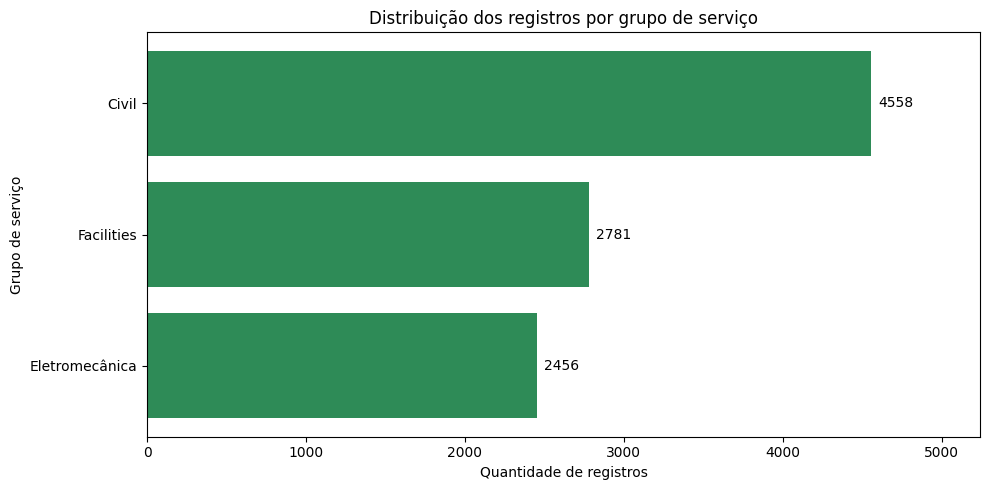

In [ ]:
plt.figure(figsize=(10, 5))

barras = plt.barh(
    frequencia_grupos.index,
    frequencia_grupos.values,
    color="seagreen"
)

plt.title("Distribuição dos registros por grupo de serviço")
plt.xlabel("Quantidade de registros")
plt.ylabel("Grupo de serviço")

plt.bar_label(barras, padding=5)

plt.gca().invert_yaxis()
plt.xlim(0, frequencia_grupos.max() * 1.15)
plt.tight_layout()
plt.show()

### 3.6.1 Resultados e interpretação da distribuição

Ao analisar a distribuição dos registros, identifiquei que a base possui três grupos de serviço:

- **Civil:** 4.558 registros (46,53%)
- **Facilities:** 2.781 registros (28,39%)
- **Eletromecânica:** 2.456 registros (25,07%)

O grupo Civil possui a maior quantidade de registros, representando quase metade da base analisada.

Já os grupos Facilities e Eletromecânica possuem quantidades menores, mas também representam uma parte importante dos serviços cadastrados.

Com essa análise, consegui entender melhor como os registros estão distribuídos e identificar quais grupos possuem maior volume de informações.

Isso também pode ajudar nas próximas investigações, porque podemos verificar se determinados padrões ou possíveis inconsistências aparecem com mais frequência em algum desses grupos.

### 3.7 Análise inicial de padrões textuais nas descrições

Nesta etapa, vou analisar alguns termos que aparecem nas descrições dos serviços para entender melhor como eles estão escritos na base.

Vou procurar palavras e abreviações como "SV", "HORA", "MÊS", "DIURNO" e "NOTURNO", para verificar quantas vezes aparecem nos registros.

Quero identificar padrões na forma como os serviços são descritos e observar se existem informações relacionadas aos horários ou às condições de execução.

Essa análise pode ajudar a entender quais informações precisam de atenção durante a padronização dos textos, principalmente para não juntar serviços que possuem características diferentes.

In [ ]:
descricoes = df["Descrição do Item"].fillna("").str.upper()

termos = ["SV", "HORA", "MÊS", "DIURNO", "NOTURNO"]

resultados = {}

for termo in termos:
    resultados[termo] = descricoes.str.contains(
        termo,
        regex=False
    ).sum()

tabela_termos = pd.DataFrame(
    resultados.items(),
    columns=["Termo", "Quantidade de registros"]
)

display(tabela_termos)

,Termo,Quantidade de registros
0,SV,4259
1,HORA,1797
2,MÊS,107
3,DIURNO,51
4,NOTURNO,89


### 3.7.1 Resultados e interpretação dos padrões textuais

Ao analisar as descrições dos serviços, encontrei os seguintes resultados:

- **SV:** 4.259 registros (43,48%)
- **HORA:** 1.797 registros (18,35%)
- **MÊS:** 107 registros (1,09%)
- **DIURNO:** 51 registros (0,52%)
- **NOTURNO:** 89 registros (0,91%)

O termo "SV" foi o que mais apareceu entre os pesquisados, seguido por "HORA".

Também encontrei descrições que possuem referências a períodos e horários, como "MÊS", "DIURNO" e "NOTURNO".

Esses resultados chamaram minha atenção porque algumas dessas informações podem ser importantes para diferenciar os serviços, principalmente quando estão relacionadas ao horário de execução.

Por exemplo, um serviço realizado no período diurno pode ter condições diferentes de um serviço realizado no período noturno.

**O que concluí:**

A análise mostrou que existem termos e abreviações recorrentes nas descrições da base.

Esses padrões podem ajudar na organização e na padronização dos textos, mas é importante tomar cuidado para não remover ou alterar informações que possam diferenciar um serviço de outro.

Também preciso considerar que essa busca identifica apenas trechos de texto. Por isso, os resultados não representam uma classificação definitiva dos serviços e um mesmo registro pode aparecer em mais de uma contagem.

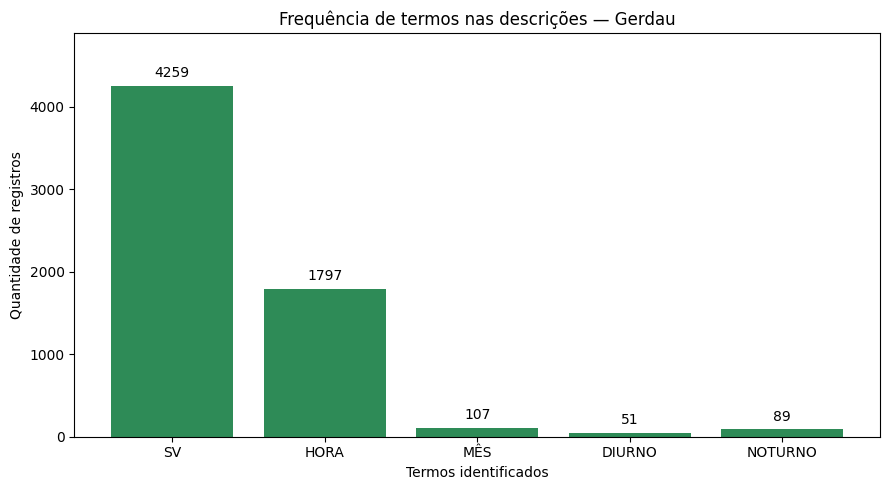

In [ ]:
plt.figure(figsize=(9, 5))

barras = plt.bar(
    tabela_termos["Termo"],
    tabela_termos["Quantidade de registros"],
    color="seagreen"
)

plt.title("Frequência de termos nas descrições — Gerdau")
plt.xlabel("Termos identificados")
plt.ylabel("Quantidade de registros")

plt.bar_label(barras, padding=4)

plt.ylim(
    0,
    tabela_termos["Quantidade de registros"].max() * 1.15
)

plt.tight_layout()
plt.show()

## 4. Conclusão preliminar da Análise Exploratória de Dados

Depois de realizar a análise exploratória da base original da Gerdau, consegui entender melhor como os dados estão organizados e identificar alguns pontos que precisam de atenção.

A base possui **9.795 registros e 5 colunas**, com **7.937 códigos de serviço diferentes**. Desses códigos, **1.234 aparecem mais de uma vez**.

Na primeira verificação, não encontrei valores ausentes nem linhas completamente duplicadas.

Ao investigar a relação entre os códigos e as descrições, encontrei **1 código associado a duas descrições diferentes** e **375 descrições iguais associadas a mais de um código de serviço**.

Um dos casos que mais chamou minha atenção foi o serviço **"SV - FURAÇÃO EM CONCRETO COM COROA DIAM"**, que possui 13 códigos diferentes, mesmo apresentando o mesmo fornecedor, grupo de serviço, descrição e unidade de medida.

Esse caso pode indicar uma possível repetição no cadastro, mas ainda precisa ser validado para entender se existem diferenças técnicas que não aparecem na planilha.

Também identifiquei que os registros estão divididos em três grupos: **Civil (46,53%)**, **Facilities (28,39%)** e **Eletromecânica (25,07%)**.

Por último, analisei alguns termos presentes nas descrições, como "SV", "HORA", "MÊS", "DIURNO" e "NOTURNO". Essa análise mostrou que existem padrões de escrita e referências a horários que podem ser importantes para diferenciar os serviços.

### O que concluí

Com essa primeira análise, percebi que a base possui situações que merecem uma investigação mais detalhada, principalmente em relação aos códigos repetidos, às descrições iguais e à padronização dos textos.

Porém, não posso considerar essas situações como erros automaticamente, porque podem existir regras de negócio ou características técnicas que não estão disponíveis na planilha.

### Próximos passos

- Investigar melhor as descrições associadas a códigos diferentes.
- Verificar quais casos podem representar possíveis duplicidades.
- Analisar as abreviações e diferenças na escrita dos serviços.
- Comparar a base original com a base tratada pelo Leonardo.
- Entender como os critérios de similaridade podem ajudar a identificar serviços semelhantes.

**Conclusão:** finalizei a primeira análise exploratória da base original e identifiquei pontos importantes que poderão ser aprofundados nas próximas etapas do desafio.

# 5. Análise exploratória da base tratada — Leonardo

### 5.1 Objetivo

Depois de analisar a base original da Gerdau, vou investigar a planilha tratada pelo Leonardo para entender como os dados foram organizados e classificados.

Quero comparar as duas bases e observar quais informações foram acrescentadas, como as descrições foram padronizadas e de que forma os serviços foram agrupados.

Também vou verificar possíveis repetições, níveis de similaridade e diferenças relacionadas aos horários ou às condições de execução.

O objetivo dessa comparação é entender melhor os resultados do tratamento realizado pela equipe e identificar situações que ainda precisam de revisão ou validação.

Essa análise vai contribuir para o diagnóstico da qualidade dos dados que estamos desenvolvendo na Sprint 2.

In [ ]:
import pandas as pd
from google.colab import files

arquivos_leo = files.upload()
nome_arquivo_leo = next(iter(arquivos_leo))

excel_leo = pd.ExcelFile(nome_arquivo_leo)

print("Abas encontradas:")
print(excel_leo.sheet_names)

df_leo = pd.read_excel(
    nome_arquivo_leo,
    sheet_name="Classificacao_9795"
)

print("\nDimensões da base tratada:")
print(df_leo.shape)

print("\nColunas disponíveis:")
display(pd.DataFrame({"Coluna": df_leo.columns}))

print("\nPrimeiros registros:")
display(df_leo.head())

Saving levantamento_padronizacao_servicos(1).xlsx to levantamento_padronizacao_servicos(1) (1).xlsx
Abas encontradas:
['Classificacao_9795', 'Grupos_Semanticos', 'Resumo_Metodo', 'Padroes_Horario', 'Metodologia']

Dimensões da base tratada:
(9795, 13)

Colunas disponíveis:


,Coluna
0,ID Linha
1,Grupo de Serviço
2,Código do Fornecedor
3,Código do Serviço
4,Descrição do Item
5,Unidade medida
6,Descrição Normalizada
7,Grupo Semântico
8,Rótulo candidato
9,Similaridade melhor vizinho



Primeiros registros:


,ID Linha,Grupo de Serviço,Código do Fornecedor,Código do Serviço,Descrição do Item,Unidade medida,Descrição Normalizada,Grupo Semântico,Rótulo candidato,Similaridade melhor vizinho,Confiança da similaridade,Descrição mais próxima,Motivo da classificação
0,1,Civil,200982674,4033776,SV-EQUIPE TELHADO,SV,SV EQUIPE TELHADO,0,NaN,0.503399,Baixa,SV-EQUIPE TELHAD (MENSAL),Mesmo grupo (Civil) e unidade (SV); similarida...
1,2,Civil,201464634,4012475,DIARIA RESGATISTA NIVEL 3 ATE 8H .,SV,DIARIA RESGATISTA NIVEL 3 ATE 8H,0,NaN,0.719432,Baixa,DIARIA RESGATISTA NIVEL 3 ATE 8 HS FDS/N,Mesmo grupo (Civil) e unidade (SV); similarida...
2,3,Civil,200772986,4050934,SV OFICIAL MENSAL,SV,SV OFICIAL MENSAL,0,NaN,0.000000,Sem vizinho elegível,NaN,Nenhum vizinho com mesmo Grupo de Serviço e Un...
3,4,Civil,300623388,4097173,Pavimentação a frio por kg,KG,PAVIMENTACAO A FRIO POR KG,0,NaN,0.159221,Baixa,SV IMPERMEABILIZANTE ACRILICO A FRIO,Mesmo grupo (Civil) e unidade (KG); similarida...
4,5,Civil,200982674,4066840,SV-EQUIPE PINTURA,SV,SV EQUIPE PINTURA,0,NaN,0.488601,Baixa,SV-EQUIPE TELHADO,Mesmo grupo (Civil) e unidade (SV); similarida...


**Resultado da importação:**

Ao carregar a planilha tratada pelo Leonardo, identifiquei **9.795 registros e 13 colunas**.

A quantidade de registros é a mesma da base original, mas a planilha tratada possui oito colunas adicionais.

Essas novas informações incluem descrições normalizadas, grupos semânticos e resultados relacionados à similaridade entre os serviços.

Também identifiquei cinco abas na planilha, sendo que, neste primeiro momento, vou utilizar a aba "Classificacao_9795" para continuar a análise.

Com isso, consigo começar a comparar os dados originais com os resultados do tratamento realizado pelo Leonardo.

### 5.2 Análise da normalização textual

Nesta etapa, vou analisar como as descrições dos serviços ficaram depois do tratamento realizado pelo Leonardo.

Para isso, vou comparar a coluna "Descrição do Item", que contém o texto original, com a coluna "Descrição Normalizada", que contém o texto depois da padronização.

Quero descobrir quantas descrições foram modificadas e observar alguns exemplos para entender quais mudanças foram feitas.

Essa comparação vai me ajudar a entender como a padronização dos textos pode facilitar a identificação de serviços com descrições parecidas.

In [ ]:
descricoes_alteradas = (
    df_leo["Descrição do Item"].fillna("")
    != df_leo["Descrição Normalizada"].fillna("")
)

total_alteradas = descricoes_alteradas.sum()

percentual_alteradas = (
    total_alteradas / len(df_leo)
) * 100

print("Total de registros:", len(df_leo))
print("Descrições alteradas:", total_alteradas)
print(f"Percentual de alterações: {percentual_alteradas:.2f}%")

print("\nExemplos de normalização:")

display(
    df_leo.loc[
        descricoes_alteradas,
        ["Descrição do Item", "Descrição Normalizada"]
    ].head(15)
)

Total de registros: 9795
Descrições alteradas: 8659
Percentual de alterações: 88.40%

Exemplos de normalização:


,Descrição do Item,Descrição Normalizada
0,SV-EQUIPE TELHADO,SV EQUIPE TELHADO
1,DIARIA RESGATISTA NIVEL 3 ATE 8H .,DIARIA RESGATISTA NIVEL 3 ATE 8H
3,Pavimentação a frio por kg,PAVIMENTACAO A FRIO POR KG
4,SV-EQUIPE PINTURA,SV EQUIPE PINTURA
6,ELETRICISTA - ROTINA,ELETRICISTA ROTINA
8,SV-HORA OFICIAL-HR NORMAL,SV HORA OFICIAL HR NORMAL
9,Diaria resgatista turno de ate 8 horas .,DIARIA RESGATISTA TURNO DE ATE 8 HORAS
10,DIARIA RESGATISTA ATE 8 HS FDS/NOT .,DIARIA RESGATISTA ATE 8 HS FDS NOT
12,PINTOR - ROTINA,PINTOR ROTINA
13,DIARIA RESGATISTA NIVEL 3 ATE 8 HS FDS/N,DIARIA RESGATISTA NIVEL 3 ATE 8 HS FDS N


### 5.2.1 Resultados e interpretação da normalização textual

Ao comparar as descrições originais com as descrições normalizadas, encontrei **8.659 registros que tiveram alguma alteração no texto**, representando **88,40% da base**.

Os outros **1.136 registros (11,60%)** permaneceram com as descrições iguais.

Ao observar alguns exemplos, percebi que o tratamento realizou mudanças como:

- Transformar letras minúsculas em maiúsculas.
- Remover acentos.
- Remover ou substituir sinais de pontuação.
- Substituir hífens por espaços.
- Retirar pontuação no final das descrições.

Essas mudanças ajudam a deixar os textos mais uniformes, facilitando a comparação entre descrições que podem ter sido escritas de formas diferentes.

Porém, é importante lembrar que **8.659 descrições alteradas não significam 8.659 erros corrigidos**. Muitas dessas mudanças são apenas na forma como o texto está escrito.

Também é necessário ter cuidado com a remoção de símbolos, porque alguns deles podem representar informações importantes para diferenciar os serviços.

**O que concluí:**

A normalização textual pode ajudar na identificação de descrições semelhantes, mas ainda preciso verificar se as alterações preservaram as informações importantes dos serviços.

Além disso, ter descrições parecidas não significa necessariamente que os serviços sejam equivalentes. Essa conclusão depende de outras análises e das regras de negócio da Gerdau.

### 5.3 Distribuição das classificações de similaridade

Depois de analisar as descrições normalizadas, vou verificar como os registros foram classificados em relação à similaridade entre os serviços.

Para isso, vou utilizar a coluna "Confiança da similaridade" da planilha tratada pelo Leonardo.

Quero identificar quais classificações aparecem na base, quantos registros existem em cada uma e qual porcentagem representam.

Essa análise vai me ajudar a entender melhor os resultados da comparação entre os serviços e identificar quais casos podem precisar de uma revisão mais detalhada.

In [ ]:
frequencia_confianca = (
    df_leo["Confiança da similaridade"]
    .value_counts(dropna=False)
)

percentual_confianca = (
    df_leo["Confiança da similaridade"]
    .value_counts(normalize=True, dropna=False) * 100
)

resumo_confianca = pd.DataFrame({
    "Quantidade": frequencia_confianca,
    "Percentual (%)": percentual_confianca.round(2)
})

print("Distribuição das classificações de similaridade:")
display(resumo_confianca)

Distribuição das classificações de similaridade:


,Quantidade,Percentual (%)
Confiança da similaridade,,
Baixa,3680,37.57
Média,2329,23.78
Revisão,2002,20.44
Alta,1467,14.98
Sem vizinho elegível,317,3.24


### 5.3.1 Resultados e interpretação das classificações de similaridade

Ao analisar a coluna "Confiança da similaridade", encontrei cinco classificações diferentes:

- **Baixa:** 3.680 registros (37,57%).
- **Média:** 2.329 registros (23,78%).
- **Revisão:** 2.002 registros (20,44%).
- **Alta:** 1.467 registros (14,98%).
- **Sem vizinho elegível:** 317 registros (3,24%).

A classificação que mais apareceu foi "Baixa", seguida por "Média" e "Revisão".

Também observei que 1.467 registros receberam a classificação "Alta", indicando que apresentaram resultados de similaridade mais elevados conforme os critérios utilizados pelo Leonardo.

Já os registros classificados como "Revisão" merecem atenção, porque fazem parte dos casos que precisam ser avaliados com mais cuidado.

A classificação "Sem vizinho elegível" indica que não foi encontrado um registro que atendesse aos critérios definidos para participar da comparação.

**O que concluí:**

Essa análise me ajudou a entender como os resultados de similaridade estão distribuídos na base tratada.

Porém, uma classificação de similaridade alta não significa que dois serviços sejam automaticamente iguais. Ainda é necessário verificar as descrições e as características dos serviços antes de confirmar uma possível equivalência.

### 5.4 Análise dos grupos semânticos

Nesta etapa, vou analisar os grupos semânticos criados na base tratada pelo Leonardo.

Esses grupos reúnem registros que foram considerados semelhantes de acordo com os critérios utilizados no processamento.

Quero descobrir quantos registros foram associados a esses grupos, quantos grupos diferentes existem e quais aparecem com mais frequência.

Também vou observar alguns exemplos para entender se os serviços agrupados possuem descrições parecidas e se existem diferenças importantes entre eles.

Essa análise vai me ajudar a identificar possíveis serviços semelhantes que precisam de uma avaliação mais detalhada.

In [ ]:
print("Identificadores de grupo mais frequentes:")
display(
    df_leo["Grupo Semântico"]
    .value_counts(dropna=False)
    .head(10)
)

registros_agrupados = df_leo[
    df_leo["Grupo Semântico"].notna()
    & (df_leo["Grupo Semântico"] != 0)
]

print("\nRegistros em grupos diferentes de zero:")
print(len(registros_agrupados))

print("\nQuantidade de grupos distintos:")
print(registros_agrupados["Grupo Semântico"].nunique())

print("\nExemplos de registros agrupados:")
display(
    registros_agrupados[
        [
            "Grupo Semântico",
            "Descrição do Item",
            "Descrição Normalizada",
            "Confiança da similaridade"
        ]
    ].head(10)
)

Identificadores de grupo mais frequentes:


,count
Grupo Semântico,
0,4058
4,107
1,91
3,72
2,64
20,55
14,50
10,47
31,46



Registros em grupos diferentes de zero:
5737

Quantidade de grupos distintos:
1122

Exemplos de registros agrupados:


,Grupo Semântico,Descrição do Item,Descrição Normalizada,Confiança da similaridade
5,463,SV ENCARREGADO MENSAL,SV ENCARREGADO MENSAL,Alta
8,956,SV-HORA OFICIAL-HR NORMAL,SV HORA OFICIAL HR NORMAL,Média
10,958,DIARIA RESGATISTA ATE 8 HS FDS/NOT .,DIARIA RESGATISTA ATE 8 HS FDS NOT,Revisão
13,958,DIARIA RESGATISTA NIVEL 3 ATE 8 HS FDS/N,DIARIA RESGATISTA NIVEL 3 ATE 8 HS FDS N,Revisão
14,961,SV TEC DE SEGURANÇA MENSAL,SV TEC DE SEGURANCA MENSAL,Revisão
18,978,SV AJUDANTE MENSAL,SV AJUDANTE MENSAL,Média
25,971,PEDREIRO - MENSAL,PEDREIRO MENSAL,Média
29,240,SV - JATEAMENTO ABRASIVO Sa 2 COM ABRASI,SV JATEAMENTO ABRASIVO SA 2 COM ABRASI,Alta
30,240,SV- JATEAMENTO ABRASIVO Sa 2 1/2 COM AB,SV JATEAMENTO ABRASIVO SA 2 1 2 COM AB,Média
31,240,SV- JATEAMENTO ABRASIVO Sa 3 COM ABRASI,SV JATEAMENTO ABRASIVO SA 3 COM ABRASI,Alta


### 5.4.1 Resultados e interpretação dos grupos semânticos

Ao analisar os grupos semânticos da base tratada pelo Leonardo, encontrei **5.737 registros associados a grupos diferentes de zero**, representando aproximadamente **58,57% da base**.

Também identifiquei **1.122 grupos semânticos diferentes** e **4.058 registros (41,43%)** classificados com o identificador zero.

Entre os grupos mais frequentes, encontrei:

- **Grupo 4:** 107 registros.
- **Grupo 1:** 91 registros.
- **Grupo 3:** 72 registros.
- **Grupo 2:** 64 registros.

Ao observar alguns exemplos, percebi que os grupos reúnem descrições parecidas, incluindo serviços relacionados a resgate e jateamento abrasivo.

Porém, também encontrei situações em que os serviços possuem diferenças que podem ser importantes, como o nível profissional ou alguma especificação técnica.

Isso chamou minha atenção porque dois serviços podem ter descrições semelhantes, mas não necessariamente representar a mesma atividade.

**O que concluí:**

Os grupos semânticos podem ajudar a encontrar possíveis repetições e serviços semelhantes na base.

Porém, antes de considerar esses registros equivalentes, é necessário verificar suas descrições, códigos, fornecedores, unidades de medida e características técnicas.

Também preciso entender melhor os critérios utilizados pelo Leonardo para interpretar corretamente os agrupamentos.

### 5.5 Verificação da metodologia de classificação

Depois de analisar os grupos semânticos, vou consultar a metodologia utilizada pelo Leonardo para entender melhor como os serviços foram classificados.

Quero identificar quais critérios foram utilizados para normalizar as descrições, calcular a similaridade e formar os grupos.

Também vou verificar como foram definidas as classificações de confiança e o que representam os identificadores dos grupos.

Essa etapa é importante porque preciso entender como o processamento foi realizado antes de interpretar os resultados ou apontar possíveis inconsistências.

In [ ]:
df_metodologia = pd.read_excel(
    nome_arquivo_leo,
    sheet_name="Metodologia"
)

print("Dimensões da aba Metodologia:")
print(df_metodologia.shape)

print("\nConteúdo da metodologia:")
display(df_metodologia)

Dimensões da aba Metodologia:
(10, 2)

Conteúdo da metodologia:


,Etapa,Procedimento
0,1. Preservação,Todas as 9.795 linhas permanecem na saída.
1,2. Normalização textual,"Texto em maiúsculas; acentos, pontuação e espa..."
2,3. Redução da unidade analítica,A análise de similaridade usa a chave Descriçã...
3,4. Representação TF-IDF,Combinação de TF-IDF por palavras (1-2 gramas)...
4,5. Busca de vizinhos,Cada descrição busca seus 7 vizinhos mais próx...
5,6. Regra de elegibilidade,Só há comparação entre registros do mesmo Grup...
6,7. Formação de grupos,"Vizinhos com similaridade >= 0,72 são conectad..."
7,8. Explicação por linha,"Cada linha recebe descrição mais próxima, scor..."
8,9. Confiança,"Alta >= 0,90; Média 0,80-0,899; Revisão 0,72-0..."
9,10. Limitação,"O agrupamento é candidato, não decisão final d..."


### 5.5.1 Resultados e interpretação da metodologia

Ao consultar a metodologia do Leonardo, consegui entender melhor como foi realizada a comparação entre os serviços.

Primeiro, as descrições passaram por uma normalização textual, com alterações como conversão para letras maiúsculas, remoção de acentos e tratamento de pontuação.

Depois, foi utilizada uma técnica chamada **TF-IDF**, que permite representar os textos numericamente para comparar suas semelhanças.

A comparação considerou palavras e sequências de caracteres, buscando identificar descrições que possuem características textuais parecidas.

Também observei que a metodologia considera o grupo de serviço e a unidade de medida para limitar quais registros podem ser comparados.

Para formar os grupos candidatos, foi utilizado um limite mínimo de similaridade de **0,72**.

As classificações de confiança foram definidas de acordo com os resultados da comparação:

- **Alta:** similaridade a partir de 0,90.
- **Média:** similaridade a partir de 0,80 e abaixo de 0,90.
- **Revisão:** similaridade a partir de 0,72 e abaixo de 0,80.
- **Baixa:** similaridade abaixo de 0,72.
- **Sem vizinho elegível:** quando não foi encontrado outro registro que atendesse aos critérios de comparação.

**O que concluí:**

A metodologia utiliza critérios para organizar e comparar as descrições dos serviços, ajudando a identificar possíveis semelhanças.

Porém, esses resultados são baseados principalmente nas características dos textos e nas regras definidas para a comparação.

Por isso, mesmo quando dois serviços possuem uma similaridade alta ou pertencem ao mesmo grupo semântico, ainda é necessário verificar se realmente representam serviços equivalentes.

### 5.6 Investigação de possíveis falsos positivos

Nesta etapa, vou investigar se alguns serviços foram colocados no mesmo grupo semântico por terem descrições parecidas, mesmo apresentando diferenças importantes.

Esses casos podem ser considerados possíveis falsos positivos, porque a similaridade entre os textos não significa necessariamente que os serviços sejam iguais.

Para entender melhor essa situação, vou analisar o grupo semântico 240, que chamou minha atenção durante a exploração dos agrupamentos.

Vou comparar os códigos, as descrições, as unidades de medida e as classificações de similaridade para verificar se existem diferenças que precisam ser consideradas.

In [ ]:
grupo_240 = df_leo[
    df_leo["Grupo Semântico"] == 240
]

print("Quantidade de registros:", len(grupo_240))

print(
    "Códigos de serviço distintos:",
    grupo_240["Código do Serviço"].nunique()
)

print(
    "Descrições normalizadas distintas:",
    grupo_240["Descrição Normalizada"].nunique()
)

print("\nExemplos do grupo 240:")

display(
    grupo_240[
        [
            "Código do Serviço",
            "Descrição do Item",
            "Descrição Normalizada",
            "Unidade medida",
            "Similaridade melhor vizinho",
            "Confiança da similaridade"
        ]
    ]
    .drop_duplicates(subset=["Descrição Normalizada"])
    .head(20)
)

Quantidade de registros: 4
Códigos de serviço distintos: 4
Descrições normalizadas distintas: 4

Exemplos do grupo 240:


,Código do Serviço,Descrição do Item,Descrição Normalizada,Unidade medida,Similaridade melhor vizinho,Confiança da similaridade
29,4027657,SV - JATEAMENTO ABRASIVO Sa 2 COM ABRASI,SV JATEAMENTO ABRASIVO SA 2 COM ABRASI,M2,0.997477,Alta
30,4027658,SV- JATEAMENTO ABRASIVO Sa 2 1/2 COM AB,SV JATEAMENTO ABRASIVO SA 2 1 2 COM AB,M2,0.824418,Média
31,4027659,SV- JATEAMENTO ABRASIVO Sa 3 COM ABRASI,SV JATEAMENTO ABRASIVO SA 3 COM ABRASI,M2,0.997477,Alta
78,4027800,SV - JATEAMENTO ABRASIVO Sa 1 COM ABRA,SV JATEAMENTO ABRASIVO SA 1 COM ABRA,M2,0.824155,Média


### 5.6.1 Estudo de caso — Grupo semântico 240

Ao analisar o grupo semântico 240, encontrei **4 registros, com 4 códigos de serviço diferentes e 4 descrições normalizadas distintas**.

Todos estão relacionados a serviços de jateamento abrasivo e utilizam a unidade de medida M2.

Porém, ao observar as descrições, percebi que cada serviço possui um grau diferente de preparação da superfície:

- **Código 4027657:** jateamento abrasivo Sa 2 — confiança Alta.
- **Código 4027658:** jateamento abrasivo Sa 2 1/2 — confiança Média.
- **Código 4027659:** jateamento abrasivo Sa 3 — confiança Alta.
- **Código 4027800:** jateamento abrasivo Sa 1 — confiança Média.

O que chamou minha atenção foi que, mesmo apresentando especificações técnicas diferentes, esses serviços foram colocados no mesmo grupo semântico.

Isso pode acontecer porque as descrições possuem muitas palavras em comum, fazendo com que o método identifique uma semelhança entre elas.

Porém, os graus de preparação da superfície podem representar requisitos de execução diferentes.

**O que concluí:**

Esse grupo é um exemplo de possível falso positivo caso os registros sejam considerados automaticamente equivalentes.

O agrupamento ajuda a encontrar serviços relacionados, mas não significa que todos possam ser tratados como o mesmo serviço.

Por isso, considero importante manter os códigos originais e validar essas diferenças técnicas antes de sugerir qualquer alteração no cadastro.

### 5.7 Investigação de diferenças nas condições de execução

Depois de investigar as diferenças técnicas entre serviços agrupados, vou analisar possíveis diferenças relacionadas às condições de execução.

Para isso, vou procurar grupos semânticos que possuem descrições com os termos "NORMAL" e "EXTRA".

Quero verificar se serviços relacionados a horas normais e horas extras foram colocados no mesmo grupo, mesmo podendo representar condições de execução ou cobrança diferentes.

Essa análise é importante porque, no contexto do desafio da Gerdau, as informações relacionadas aos tipos de hora precisam ser consideradas com cuidado.

Por enquanto, vou utilizar esses termos apenas para encontrar grupos que merecem investigação, sem considerar que todos possuem erros.

In [ ]:
agrupados = df_leo[
    df_leo["Grupo Semântico"].notna()
    & (df_leo["Grupo Semântico"] != 0)
].copy()

agrupados["Tem NORMAL"] = (
    agrupados["Descrição Normalizada"]
    .fillna("")
    .str.contains("NORMAL", case=False, regex=False)
)

agrupados["Tem EXTRA"] = (
    agrupados["Descrição Normalizada"]
    .fillna("")
    .str.contains("EXTRA", case=False, regex=False)
)

grupos_horario = agrupados.groupby("Grupo Semântico")[
    ["Tem NORMAL", "Tem EXTRA"]
].any()

grupos_suspeitos = grupos_horario[
    grupos_horario["Tem NORMAL"]
    & grupos_horario["Tem EXTRA"]
]

print(
    "Grupos com ocorrências de NORMAL e EXTRA:",
    len(grupos_suspeitos)
)

ids_suspeitos = grupos_suspeitos.index[:5]

exemplos = agrupados[
    agrupados["Grupo Semântico"].isin(ids_suspeitos)
]

display(
    exemplos[
        [
            "Grupo Semântico",
            "Código do Serviço",
            "Descrição Normalizada",
            "Confiança da similaridade"
        ]
    ]
    .sort_values("Grupo Semântico")
    .head(30)
)

Grupos com ocorrências de NORMAL e EXTRA: 64


,Grupo Semântico,Código do Serviço,Descrição Normalizada,Confiança da similaridade
224,1,4100640,SUPERVISOR HORA EXTRA CHEIA,Revisão
383,1,4100642,SUPERVISOR HORA NOT CHEIA,Revisão
432,1,4100645,SUPERVISOR HORA EXTRA NOT,Média
478,1,4100572,AUX TST HORA EXTRA CHEIA,Revisão
528,1,4100674,LIDER ANDAIME HORA EXTRA CHEIA,Revisão
536,1,4100574,AUX TST HORA NOT CHEIA,Revisão
558,1,4100577,AUX TST HORA EXTRA NOT,Média
580,1,4100679,LIDER ANDAIME HORA EXTRA NOT,Média
2583,1,4100579,AUX TST HORA EXTRA NOT A DISPOSICAO,Média
2588,1,4100586,SUPERVISOR TST HORA NORMAL,Revisão


### 5.7.1 Resultados e interpretação das diferenças nas condições de execução

Ao analisar os grupos semânticos, encontrei **64 grupos que possuem ocorrências dos termos "NORMAL" e "EXTRA"** em suas descrições.

Para entender melhor esses resultados, observei o grupo semântico 1, que reúne serviços relacionados à função de supervisor TST.

Entre as descrições encontradas, estão:

- SUPERVISOR TST HORA NORMAL
- SUPERVISOR TST HORA EXTRA RESIDUAL
- SUPERVISOR TST HORA EXTRA CHEIA
- SUPERVISOR TST HORA NOT CHEIA
- SUPERVISOR TST HORA EXTRA NOT

Percebi que esses serviços possuem descrições parecidas, mas apresentam diferenças relacionadas ao tipo de hora e às condições de execução.

Isso chamou minha atenção porque uma hora normal, uma hora extra e uma hora noturna podem seguir regras de cobrança ou apuração diferentes.

Mesmo assim, esses registros podem acabar no mesmo grupo por compartilharem termos semelhantes, como o nome da função e a palavra "HORA".

**O que concluí:**

Os 64 grupos encontrados são candidatos a uma investigação mais detalhada, mas isso não significa que existam 64 erros.

Essa análise mostrou que precisamos ter cuidado ao comparar serviços relacionados a horários, porque pequenas diferenças nas descrições podem representar condições importantes.

Por isso, considero necessário preservar informações como hora normal, hora extra e período noturno durante a padronização.

Os agrupamentos podem ajudar a identificar serviços da mesma família, mas a confirmação de equivalência depende das regras de negócio da Gerdau.

### 5.8 Quantificação dos registros em grupos com diferentes condições de horário

Depois de identificar os 64 grupos semânticos que possuem descrições com os termos "NORMAL" e "EXTRA", vou verificar quantos registros fazem parte desses grupos.

Quero descobrir qual porcentagem da base eles representam e identificar quais grupos possuem a maior quantidade de registros.

Essa análise vai me ajudar a entender o tamanho desse conjunto de dados e quais grupos podem ser investigados primeiro.

É importante lembrar que esses grupos foram selecionados por apresentarem determinados termos nas descrições, e não porque possuem erros confirmados.

In [ ]:
ids_grupos_horario = grupos_suspeitos.index

registros_horario = agrupados[
    agrupados["Grupo Semântico"].isin(ids_grupos_horario)
]

total_registros_horario = len(registros_horario)

percentual_horario = (
    total_registros_horario / len(df_leo)
) * 100

print("Grupos identificados:", len(ids_grupos_horario))

print(
    "Total de registros pertencentes a esses grupos:",
    total_registros_horario
)

print(
    f"Percentual da base: {percentual_horario:.2f}%"
)

print("\nGrupos com maior quantidade de registros:")

display(
    registros_horario["Grupo Semântico"]
    .value_counts()
    .head(10)
    .rename_axis("Grupo Semântico")
    .reset_index(name="Quantidade de registros")
)

Grupos identificados: 64
Total de registros pertencentes a esses grupos: 762
Percentual da base: 7.78%

Grupos com maior quantidade de registros:


,Grupo Semântico,Quantidade de registros
0,4,107
1,1,91
2,31,46
3,40,42
4,179,34
5,114,30
6,8,30
7,196,24
8,295,20
9,60,18


### 5.8.1 Resultados e interpretação da abrangência dos agrupamentos

Ao analisar os grupos que possuem ocorrências dos termos "NORMAL" e "EXTRA", identifiquei **64 grupos semânticos**, que juntos possuem **762 registros**.

Esses registros representam aproximadamente **7,78% dos 9.795 registros da base tratada**.

Os grupos com maior quantidade de registros foram:

- **Grupo 4:** 107 registros.
- **Grupo 1:** 91 registros.
- **Grupo 31:** 46 registros.
- **Grupo 40:** 42 registros.
- **Grupo 179:** 34 registros.

Com esses resultados, consegui entender melhor quantos registros estão envolvidos nos agrupamentos identificados anteriormente.

Também percebi que alguns grupos possuem uma quantidade maior de registros, o que pode ajudar a definir quais devem ser analisados primeiro.

Porém, é importante destacar que os **762 registros representam todas as linhas pertencentes aos 64 grupos**, incluindo descrições que não possuem diretamente os termos "NORMAL" ou "EXTRA".

Isso significa que não encontrei 762 erros ou duplicidades. Encontrei 762 registros que pertencem a grupos que podem precisar de uma investigação mais detalhada.

**O que concluí:**

Essa análise mostrou que existe uma parte da base que merece atenção por reunir serviços relacionados a diferentes condições de execução.

Os grupos com mais registros podem ser priorizados para verificar se informações importantes, como horas normais, extras e noturnas, estão sendo preservadas.

Para confirmar se existem inconsistências, ainda é necessário analisar os serviços individualmente e considerar as regras de negócio da Gerdau.

### 5.9 Comparação entre a base original e a base tratada

Nesta etapa, vou comparar a base original da Gerdau com a base tratada pelo Leonardo para verificar se as informações originais foram preservadas.

Quero conferir se as duas bases possuem a mesma quantidade de registros e de códigos de serviço diferentes.

Também vou comparar as cinco colunas originais, linha por linha, para identificar se alguma informação foi modificada durante o tratamento.

Essa verificação é importante porque precisamos garantir que os dados originais continuem disponíveis para consulta, mesmo depois da normalização e da classificação dos serviços.

In [ ]:
colunas_originais = [
    "Grupo de Serviço",
    "Código do Fornecedor",
    "Código do Serviço",
    "Descrição do Item",
    "Unidade medida"
]

print("Registros na base original:", len(df))
print("Registros na base do Leo:", len(df_leo))

print(
    "\nCódigos distintos na base original:",
    df["Código do Serviço"].nunique()
)

print(
    "Códigos distintos na base do Leo:",
    df_leo["Código do Serviço"].nunique()
)

base_original = df[colunas_originais].reset_index(drop=True)
base_tratada = df_leo[colunas_originais].reset_index(drop=True)

if len(base_original) == len(base_tratada):

    comparacao = base_original.eq(base_tratada)

    comparacao = comparacao | (
        base_original.isna() & base_tratada.isna()
    )

    linhas_iguais = comparacao.all(axis=1)

    print("\nLinhas com campos originais idênticos:",
          linhas_iguais.sum())

    print("Linhas com alguma diferença:",
          (~linhas_iguais).sum())

else:
    print("\nAs bases possuem quantidades diferentes de linhas.")

Registros na base original: 9795
Registros na base do Leo: 9795

Códigos distintos na base original: 7937
Códigos distintos na base do Leo: 7937

Linhas com campos originais idênticos: 9795
Linhas com alguma diferença: 0


### 5.9.1 Resultados da comparação entre as bases

Depois de comparar a base original da Gerdau com a base tratada pelo Leonardo, encontrei os seguintes resultados:

- **Registros na base original:** 9.795
- **Registros na base tratada:** 9.795
- **Códigos de serviço diferentes nas duas bases:** 7.937
- **Linhas com os cinco campos originais iguais:** 9.795
- **Linhas com alguma diferença:** 0

Para realizar essa comparação, utilizei as cinco colunas originais: grupo de serviço, código do fornecedor, código do serviço, descrição do item e unidade de medida.

O resultado mostrou que todas as informações dessas colunas permaneceram iguais nas duas bases, considerando a ordem dos registros.

Isso significa que o tratamento realizado pelo Leonardo acrescentou informações para a análise sem modificar os dados originais que foram verificados.

**O que concluí:**

Essa comparação me ajudou a confirmar que os campos originais foram preservados na base tratada.

Assim, podemos utilizar as novas colunas para investigar descrições normalizadas, similaridade e grupos semânticos, mantendo as informações originais como referência.

Porém, isso não significa que todos os agrupamentos estejam corretos. A qualidade das classificações ainda precisa ser analisada separadamente.

### 5.10 Investigação de duplicidades após normalização

Depois de verificar que os dados originais foram preservados, vou investigar possíveis repetições na base tratada pelo Leonardo.

Para isso, vou utilizar três informações: a descrição normalizada, o grupo de serviço e a unidade de medida.

Essas três colunas formam uma combinação que vou utilizar para identificar registros com as mesmas características dentro da análise.

Quero descobrir quantas combinações diferentes existem, quantas ocorrências adicionais aparecem e quantos registros fazem parte de combinações repetidas.

Essa investigação vai me ajudar a entender melhor os resultados da normalização e identificar possíveis redundâncias que precisam ser avaliadas.

É importante lembrar que uma combinação repetida não significa necessariamente que existe um erro no cadastro.

In [ ]:
chave = [
    "Descrição Normalizada",
    "Grupo de Serviço",
    "Unidade medida"
]

duplicidades_excedentes = df_leo.duplicated(
    subset=chave,
    keep="first"
).sum()

linhas_em_chaves_repetidas = df_leo.duplicated(
    subset=chave,
    keep=False
).sum()

chaves_distintas = (
    df_leo[chave]
    .drop_duplicates()
    .shape[0]
)

print("Total de registros:", len(df_leo))

print(
    "Chaves distintas:",
    chaves_distintas
)

print(
    "Repetições adicionais:",
    duplicidades_excedentes
)

print(
    "Todas as linhas em chaves repetidas:",
    linhas_em_chaves_repetidas
)

print("\nExemplos de registros com chaves repetidas:")

display(
    df_leo[
        df_leo.duplicated(subset=chave, keep=False)
    ][
        chave + ["Código do Serviço"]
    ]
    .sort_values(chave)
    .head(15)
)

Total de registros: 9795
Chaves distintas: 7392
Repetições adicionais: 2403
Todas as linhas em chaves repetidas: 3891

Exemplos de registros com chaves repetidas:


,Descrição Normalizada,Grupo de Serviço,Unidade medida,Código do Serviço
6810,ADMINISTRATIVO HORA EXTRA DOM FER,Eletromecânica,H,4090073
6811,ADMINISTRATIVO HORA EXTRA DOM FER,Eletromecânica,H,4090073
6808,ADMINISTRATIVO HORA EXTRA SEM,Eletromecânica,H,4090072
6809,ADMINISTRATIVO HORA EXTRA SEM,Eletromecânica,H,4090072
6804,ADMINISTRATIVO HORA NORMAL,Eletromecânica,H,4090070
6805,ADMINISTRATIVO HORA NORMAL,Eletromecânica,H,4090070
6806,ADMINISTRATIVO HORA NOT,Eletromecânica,H,4090071
6807,ADMINISTRATIVO HORA NOT,Eletromecânica,H,4090071
7760,AG DE LIMPEZA,Facilities,SV,4099895
7806,AG DE LIMPEZA,Facilities,SV,4099910


### 5.10.1 Resultados e interpretação das duplicidades após normalização

Ao analisar as combinações de descrição normalizada, grupo de serviço e unidade de medida, encontrei os seguintes resultados:

- **Total de registros:** 9.795
- **Combinações distintas:** 7.392
- **Ocorrências adicionais:** 2.403
- **Registros pertencentes a combinações repetidas:** 3.891

Esses resultados mostram que existem registros que compartilham a mesma descrição normalizada, o mesmo grupo de serviço e a mesma unidade de medida.

As **2.403 ocorrências adicionais** representam as repetições encontradas depois de considerar a primeira ocorrência de cada combinação.

Já os **3.891 registros** representam todas as linhas que fazem parte dessas combinações repetidas, incluindo as primeiras ocorrências.

Isso corresponde a aproximadamente **39,72% da base tratada**.

O que chamou minha atenção foi a quantidade de registros que passaram a compartilhar a mesma combinação de informações após a normalização.

Porém, isso não significa que encontrei 3.891 erros, porque podem existir códigos diferentes para serviços que possuem características não representadas nessas três colunas.

**O que concluí:**

A normalização ajudou a identificar combinações repetidas que podem ser investigadas com mais detalhes.

Esses resultados podem indicar oportunidades de padronização ou possíveis redundâncias cadastrais, mas ainda precisamos verificar os códigos, fornecedores e regras de negócio antes de confirmar qualquer duplicidade.

### 5.11 Investigação de chaves normalizadas associadas a múltiplos códigos

Nesta etapa, vou investigar se existem descrições normalizadas que estão associadas a diferentes códigos de serviço.

Para isso, vou utilizar a combinação de três informações: descrição normalizada, grupo de serviço e unidade de medida.

Quero identificar quantas dessas combinações possuem mais de um código diferente e quantos registros estão envolvidos.

Essa análise vai me ajudar a encontrar possíveis repetições no cadastro, inclusive em situações em que as descrições originais foram escritas de formas diferentes.

Porém, esses resultados serão considerados apenas possíveis casos para investigação, porque códigos diferentes não significam necessariamente serviços duplicados.

### 5.11.1 Resultados e interpretação das chaves normalizadas com múltiplos códigos

Ao analisar as combinações de descrição normalizada, grupo de serviço e unidade de medida, encontrei **462 combinações associadas a mais de um código de serviço diferente**.

Essas combinações envolvem **1.570 registros**, representando aproximadamente **16,03% da base tratada**.

Um exemplo que apareceu novamente foi o serviço **"SV FURACAO EM CONCRETO COM COROA DIAM"**, do grupo Civil, com unidade de medida CM.

Essa descrição está associada a **13 códigos diferentes**, todos vinculados ao fornecedor 200303818.

Esse caso já tinha chamado minha atenção durante a análise da base original, porque os registros possuem as mesmas informações nos campos analisados, mas códigos distintos.

**O que concluí:**

A análise mostrou que existem combinações normalizadas associadas a diferentes códigos de serviço, o que pode indicar possíveis repetições no cadastro.

Porém, não posso afirmar que as 462 combinações representam erros, porque podem existir diferenças técnicas ou contratuais que não aparecem nas colunas utilizadas.

Por isso, considero importante investigar primeiro os casos com mais códigos diferentes e verificar as informações dos fornecedores, as características técnicas e as condições de execução antes de sugerir qualquer alteração.

In [ ]:
chave = [
    "Descrição Normalizada",
    "Grupo de Serviço",
    "Unidade medida"
]

codigos_por_chave = (
    df_leo
    .groupby(chave, dropna=False)["Código do Serviço"]
    .nunique()
    .reset_index(name="Quantidade de códigos distintos")
)

chaves_multiplos_codigos = codigos_por_chave[
    codigos_por_chave["Quantidade de códigos distintos"] > 1
]

print(
    "Chaves normalizadas associadas a múltiplos códigos:",
    len(chaves_multiplos_codigos)
)

exemplos_multiplos = df_leo.merge(
    chaves_multiplos_codigos,
    on=chave,
    how="inner"
)

print(
    "Registros envolvidos nessas chaves:",
    len(exemplos_multiplos)
)

print("\nExemplos de chaves com múltiplos códigos:")

display(
    exemplos_multiplos[
        chave + [
            "Código do Serviço",
            "Código do Fornecedor",
            "Quantidade de códigos distintos"
        ]
    ]
    .sort_values(
        "Quantidade de códigos distintos",
        ascending=False
    )
    .head(20)
)

Chaves normalizadas associadas a múltiplos códigos: 462
Registros envolvidos nessas chaves: 1570

Exemplos de chaves com múltiplos códigos:


,Descrição Normalizada,Grupo de Serviço,Unidade medida,Código do Serviço,Código do Fornecedor,Quantidade de códigos distintos
24,SV FURACAO EM CONCRETO COM COROA DIAM,Civil,CM,4028323,200303818,13
14,SV FURACAO EM CONCRETO COM COROA DIAM,Civil,CM,4028316,200303818,13
22,SV FURACAO EM CONCRETO COM COROA DIAM,Civil,CM,4028322,200303818,13
21,SV FURACAO EM CONCRETO COM COROA DIAM,Civil,CM,4028321,200303818,13
20,SV FURACAO EM CONCRETO COM COROA DIAM,Civil,CM,4028320,200303818,13
19,SV FURACAO EM CONCRETO COM COROA DIAM,Civil,CM,4028319,200303818,13
11,SV FURACAO EM CONCRETO COM COROA DIAM,Civil,CM,4028314,200303818,13
27,SV FURACAO EM CONCRETO COM COROA DIAM,Civil,CM,4028326,200303818,13
10,SV FURACAO EM CONCRETO COM COROA DIAM,Civil,CM,4028313,200303818,13
15,SV FURACAO EM CONCRETO COM COROA DIAM,Civil,CM,4028317,200303818,13


### 5.12 Comparação das chaves antes e depois da normalização

Depois de investigar as combinações normalizadas associadas a diferentes códigos, vou comparar esses resultados com as descrições originais.

Quero entender se a normalização textual ajudou a identificar possíveis repetições que não apareciam quando os textos eram comparados exatamente como estavam escritos.

Para fazer essa comparação, vou manter o grupo de serviço e a unidade de medida, alterando apenas a coluna utilizada para representar a descrição.

Primeiro, vou utilizar a descrição original. Depois, vou repetir a análise utilizando a descrição normalizada.

Assim, consigo observar o que mudou nos resultados após a padronização dos textos.

### 5.12.1 Resultados e interpretação do impacto da normalização

Ao comparar as descrições originais com as normalizadas, encontrei os seguintes resultados:

| Indicador | Antes da normalização | Depois da normalização |
|---|---:|---:|
| Combinações distintas | 7.518 | 7.392 |
| Combinações com mais de um código | 355 | 462 |

Depois da normalização, a quantidade de combinações distintas diminuiu de **7.518 para 7.392**, uma redução de **126 combinações (1,68%)**.

Ao mesmo tempo, a quantidade de combinações associadas a diferentes códigos aumentou de **355 para 462**, uma diferença de **107 combinações (30,14%)**.

Isso mostra que a normalização conseguiu reunir algumas descrições que antes eram consideradas diferentes por causa da forma como estavam escritas.

Com isso, mais combinações passaram a aparecer associadas a diferentes códigos de serviço.

Porém, é importante lembrar que esse aumento de 107 representa a diferença entre as duas contagens. Isso não significa que foram encontrados 107 novos erros ou duplicidades confirmadas.

**O que concluí:**

A normalização textual ajudou a identificar mais situações que podem indicar possíveis repetições no cadastro.

Mesmo assim, ainda preciso considerar que descrições iguais ou parecidas não garantem que os serviços sejam equivalentes.

Por isso, esses resultados precisam ser avaliados junto com as características técnicas e as regras de negócio da Gerdau.

In [ ]:
chave_original = [
    "Descrição do Item",
    "Grupo de Serviço",
    "Unidade medida"
]

chave_normalizada = [
    "Descrição Normalizada",
    "Grupo de Serviço",
    "Unidade medida"
]

contagem_original = (
    df_leo
    .groupby(chave_original, dropna=False)["Código do Serviço"]
    .nunique()
)

contagem_normalizada = (
    df_leo
    .groupby(chave_normalizada, dropna=False)["Código do Serviço"]
    .nunique()
)

total_original = (contagem_original > 1).sum()
total_normalizado = (contagem_normalizada > 1).sum()

print("Chaves originais com múltiplos códigos:", total_original)
print("Chaves normalizadas com múltiplos códigos:", total_normalizado)

print(
    "Diferença na quantidade de chaves:",
    total_normalizado - total_original
)

print("\nQuantidade total de chaves distintas:")
print("Antes:", len(contagem_original))
print("Depois:", len(contagem_normalizada))

Chaves originais com múltiplos códigos: 355
Chaves normalizadas com múltiplos códigos: 462
Diferença na quantidade de chaves: 107

Quantidade total de chaves distintas:
Antes: 7518
Depois: 7392


### 5.13 Exemplos de consolidação textual após normalização

Nesta etapa, vou investigar quais descrições originais diferentes passaram a ter o mesmo texto depois da normalização realizada pelo Leonardo.

Quero encontrar exemplos de palavras ou frases que estavam escritas de formas diferentes, mas que foram padronizadas para uma mesma descrição.

Também vou observar se essa padronização acabou retirando alguma informação que poderia ser importante para diferenciar os serviços.

Essa análise vai me ajudar a entender melhor os benefícios da normalização e os cuidados necessários antes de considerar duas descrições equivalentes.

### 5.13.1 Resultados e interpretação da consolidação textual

Ao analisar as descrições antes e depois da normalização, encontrei **126 combinações normalizadas que reúnem mais de uma descrição original diferente**.

Em alguns casos, percebi que a normalização ajudou a padronizar pequenas diferenças na escrita, como:

- "ARTÍFICE" e "ARTIFICE";
- "AJUDANTE (HORA NORMAL)" e "AJUDANTE - HORA NORMAL";
- "ARMADOR - HORA NORMAL A DISPOSICAO" e "ARMADOR - HORA NORMAL À DISPOSIÇÃO".

Esses exemplos mostram situações em que diferenças de acentuação ou pontuação foram eliminadas, deixando os textos mais padronizados.

Porém, também encontrei casos que chamaram minha atenção porque a normalização retirou símbolos que podem ter algum significado importante.

**Exemplo: Assistente Administrativo HE 15**

As descrições "ASSISTENTE ADMINISTRATIVO HE +15 DIURNO" e "ASSISTENTE ADMINISTRATIVO HE -15 DIURNO" passaram a ter a mesma descrição normalizada:

"ASSISTENTE ADMINISTRATIVO HE 15 DIURNO"

O mesmo aconteceu com descrições relacionadas ao período noturno.

Isso acontece porque os símbolos "+" e "-" foram removidos durante a normalização.

**O que concluí:**

A normalização ajudou a reunir descrições que possuíam diferenças simples de escrita, mas também mostrou que precisamos ter cuidado com a remoção de alguns símbolos.

Dependendo do significado de "+" e "-", essa alteração pode fazer com que serviços diferentes pareçam iguais.

Por isso, considero importante verificar quais símbolos podem ser removidos sem prejudicar as informações e quais precisam ser preservados por fazerem parte das regras de negócio da Gerdau.

In [ ]:
chave = [
    "Descrição Normalizada",
    "Grupo de Serviço",
    "Unidade medida"
]

variacoes = (
    df_leo
    .groupby(chave, dropna=False)["Descrição do Item"]
    .nunique()
    .reset_index(name="Descrições originais distintas")
)

chaves_consolidadas = variacoes[
    variacoes["Descrições originais distintas"] > 1
]

print(
    "Chaves normalizadas com múltiplas escritas originais:",
    len(chaves_consolidadas)
)

exemplos_consolidados = df_leo.merge(
    chaves_consolidadas,
    on=chave,
    how="inner"
)

display(
    exemplos_consolidados[
        [
            "Descrição do Item",
            "Descrição Normalizada",
            "Grupo de Serviço",
            "Unidade medida",
            "Código do Serviço"
        ]
    ]
    .drop_duplicates()
    .sort_values("Descrição Normalizada")
    .head(20)
)

Chaves normalizadas com múltiplas escritas originais: 126


,Descrição do Item,Descrição Normalizada,Grupo de Serviço,Unidade medida,Código do Serviço
217,AJUDANTE (HORA NORMAL),AJUDANTE HORA NORMAL,Eletromecânica,H,4101770
214,AJUDANTE (HORA NORMAL),AJUDANTE HORA NORMAL,Eletromecânica,H,4089050
199,AJUDANTE - HORA NORMAL,AJUDANTE HORA NORMAL,Eletromecânica,H,4079553
183,AJUDANTE (HORA NORMAL),AJUDANTE HORA NORMAL,Eletromecânica,H,4076400
160,ARMADOR - HORA NORMAL A DISPOSICAO,ARMADOR HORA NORMAL A DISPOSICAO,Civil,H,4086466
176,ARMADOR - HORA NORMAL À DISPOSIÇÃO,ARMADOR HORA NORMAL A DISPOSICAO,Civil,H,4096457
337,ARTÍFICE,ARTIFICE,Facilities,SV,4092270
260,ARTIFICE,ARTIFICE,Facilities,SV,4099911
338,ARTIFICE,ARTIFICE,Facilities,SV,4117541
264,ARTÍFICE,ARTIFICE,Facilities,SV,4100964


### 5.14 Investigação da remoção de símbolos potencialmente relevantes

Depois de encontrar descrições que perderam os símbolos "+" e "-" durante a normalização, vou investigar melhor onde esses sinais aparecem na base original.

Quero identificar quantos registros possuem esses símbolos e observar exemplos em que aparecem junto ao número 15.

Essa investigação vai me ajudar a entender se a remoção dos sinais pode ter feito descrições diferentes parecerem iguais.

Porém, é importante lembrar que nem todo símbolo representa uma informação importante para o serviço. Por isso, os resultados serão utilizados apenas para encontrar situações que precisam ser analisadas com mais cuidado.

In [ ]:
tem_sinal = (
    df_leo["Descrição do Item"]
    .fillna("")
    .str.contains(r"[+-]", regex=True)
)

registros_com_sinal = df_leo[tem_sinal].copy()

print(
    "Registros originais contendo + ou -:",
    len(registros_com_sinal)
)

tem_mais_15 = (
    df_leo["Descrição do Item"]
    .fillna("")
    .str.contains(r"\+\s*15", regex=True)
)

tem_menos_15 = (
    df_leo["Descrição do Item"]
    .fillna("")
    .str.contains(r"-\s*15", regex=True)
)

print("Registros contendo +15:", tem_mais_15.sum())
print("Registros contendo -15:", tem_menos_15.sum())

print("\nExemplos encontrados:")

display(
    df_leo.loc[
        tem_mais_15 | tem_menos_15,
        [
            "Código do Serviço",
            "Descrição do Item",
            "Descrição Normalizada",
            "Grupo Semântico"
        ]
    ].head(20)
)

Registros originais contendo + ou -: 4764
Registros contendo +15: 2
Registros contendo -15: 19

Exemplos encontrados:


,Código do Serviço,Descrição do Item,Descrição Normalizada,Grupo Semântico
489,4023704,"SV-REGISTRO GAVETA BRUTO 3/4""-1502 B",SV REGISTRO GAVETA BRUTO 3 4 1502 B,146
538,4023794,"SV-VÁLVULA ESFERA BRUTA 3/4""-1552 B",SV VALVULA ESFERA BRUTA 3 4 1552 B,317
584,4023701,"SV-REGISTRO GAVETA BRUTO 1""-1502 B",SV REGISTRO GAVETA BRUTO 1 1502 B,146
611,4023793,"SV-VÁLVULA ESFERA BRUTA 1/2""-1552 B",SV VALVULA ESFERA BRUTA 1 2 1552 B,317
1069,4023699,"SV-REGISTRO GAVETA BRUTO 1 1/2""-1502 B",SV REGISTRO GAVETA BRUTO 1 1 2 1502 B,146
1071,4023792,"SV-VÁLVULA ESFERA BRUTA 1""-1552B",SV VALVULA ESFERA BRUTA 1 1552B,317
1073,4023702,"SV-REGISTRO GAVETA BRUTO 1/2""-1502 B",SV REGISTRO GAVETA BRUTO 1 2 1502 B,146
1087,4023700,"SV-REGISTRO GAVETA BRUTO 1 1/4""-1502 B",SV REGISTRO GAVETA BRUTO 1 1 4 1502 B,146
1088,4023982,"SV-REGISTRO DE GAVETA BRUTO 1 1/2"" - 150",SV REGISTRO DE GAVETA BRUTO 1 1 2 150,51
1089,4023703,"SV-REGISTRO GAVETA BRUTO 2""-1502 B",SV REGISTRO GAVETA BRUTO 2 1502 B,146


### 5.14.1 Resultados e interpretação da remoção de símbolos

Ao investigar os símbolos "+" e "-" nas descrições originais, encontrei **4.764 registros contendo pelo menos um desses sinais**, representando aproximadamente **48,64% da base**.

Na primeira busca, encontrei 2 registros contendo "+15" e 19 contendo "-15". Porém, percebi que essa pesquisa também poderia encontrar descrições que não estavam relacionadas às condições de execução.

Por isso, refinei a busca para procurar especificamente as expressões "HE +15" e "HE -15".

Com essa alteração, encontrei:

- **2 registros com "HE +15";**
- **4 registros com "HE -15".**

Ao analisar os resultados, percebi que os 6 registros pertencem ao **grupo semântico 613** e estão associados a **4 códigos de serviço diferentes**.

Também identifiquei que as descrições originais de Assistente Administrativo com "HE +15" e "HE -15" passaram a ter o mesmo texto após a normalização.

Isso aconteceu tanto nos serviços diurnos quanto nos noturnos.

Por exemplo:

- "ASSISTENTE ADMINISTRATIVO HE +15 DIURNO"
- "ASSISTENTE ADMINISTRATIVO HE -15 DIURNO"

As duas descrições foram transformadas em:

"ASSISTENTE ADMINISTRATIVO HE 15 DIURNO"

**O que chamou minha atenção:**

A normalização removeu os sinais "+" e "-", fazendo com que descrições originalmente diferentes passassem a ser representadas pelo mesmo texto.

Ainda não é possível afirmar qual é o significado operacional desses sinais sem consultar as regras de negócio da Gerdau.

Porém, essa diferença merece atenção, porque pode representar condições distintas de execução ou cobrança.

**O que concluí:**

A investigação confirmou que a normalização eliminou a diferença textual entre os sinais "+" e "-" nesse conjunto de registros.

Isso não significa que os códigos estejam errados ou que os serviços sejam necessariamente equivalentes.

Por isso, considero importante preservar esses símbolos quando puderem representar informações relevantes e validar seu significado antes de sugerir alterações no cadastro.

Esse exemplo mostra que a normalização textual precisa considerar não apenas a escrita das descrições, mas também as informações que podem ser importantes para o negócio.

In [ ]:
descricao = df_leo["Descrição do Item"].fillna("")

tem_mais_15 = descricao.str.contains(
    r"\bHE\s*\+\s*15\b",
    regex=True
)

tem_menos_15 = descricao.str.contains(
    r"\bHE\s*-\s*15\b",
    regex=True
)

print("Registros com HE +15:", tem_mais_15.sum())
print("Registros com HE -15:", tem_menos_15.sum())

display(
    df_leo.loc[
        tem_mais_15 | tem_menos_15,
        [
            "Código do Serviço",
            "Descrição do Item",
            "Descrição Normalizada",
            "Grupo Semântico"
        ]
    ]
)

display(
    casos_he_15[
        [
            "Código do Serviço",
            "Descrição do Item",
            "Descrição Normalizada",
            "Grupo Semântico"
        ]
    ]
)

Registros com HE +15: 2
Registros com HE -15: 4


,Código do Serviço,Descrição do Item,Descrição Normalizada,Grupo Semântico
8833,4096487,ASSISTENTE ADMINISTRATIVO HE +15 DIURNO,ASSISTENTE ADMINISTRATIVO HE 15 DIURNO,613
8834,4096910,ASSISTENTE ADMINISTRATIVO HE +15 NOTURNO,ASSISTENTE ADMINISTRATIVO HE 15 NOTURNO,613
8945,4096488,ASSISTENTE ADMINISTRATIVO HE -15 DIURNO,ASSISTENTE ADMINISTRATIVO HE 15 DIURNO,613
8946,4096488,ASSISTENTE ADMINISTRATIVO HE -15 DIURNO,ASSISTENTE ADMINISTRATIVO HE 15 DIURNO,613
8947,4096489,ASSISTENTE ADMINISTRATIVO HE -15 NOTURNO,ASSISTENTE ADMINISTRATIVO HE 15 NOTURNO,613
8948,4096489,ASSISTENTE ADMINISTRATIVO HE -15 NOTURNO,ASSISTENTE ADMINISTRATIVO HE 15 NOTURNO,613


,Código do Serviço,Descrição do Item,Descrição Normalizada,Grupo Semântico
8833,4096487,ASSISTENTE ADMINISTRATIVO HE +15 DIURNO,ASSISTENTE ADMINISTRATIVO HE 15 DIURNO,613
8834,4096910,ASSISTENTE ADMINISTRATIVO HE +15 NOTURNO,ASSISTENTE ADMINISTRATIVO HE 15 NOTURNO,613
8945,4096488,ASSISTENTE ADMINISTRATIVO HE -15 DIURNO,ASSISTENTE ADMINISTRATIVO HE 15 DIURNO,613
8946,4096488,ASSISTENTE ADMINISTRATIVO HE -15 DIURNO,ASSISTENTE ADMINISTRATIVO HE 15 DIURNO,613
8947,4096489,ASSISTENTE ADMINISTRATIVO HE -15 NOTURNO,ASSISTENTE ADMINISTRATIVO HE 15 NOTURNO,613
8948,4096489,ASSISTENTE ADMINISTRATIVO HE -15 NOTURNO,ASSISTENTE ADMINISTRATIVO HE 15 NOTURNO,613


In [ ]:
resumo_he_15 = (
    casos_he_15
    .groupby("Descrição Normalizada")
    .agg(
        Registros=("Código do Serviço", "size"),
        Codigos_distintos=("Código do Serviço", "nunique"),
        Descricoes_originais=("Descrição do Item", "nunique")
    )
    .reset_index()
)

display(resumo_he_15)

,Descrição Normalizada,Registros,Codigos_distintos,Descricoes_originais
0,ASSISTENTE ADMINISTRATIVO HE 15 DIURNO,3,2,2
1,ASSISTENTE ADMINISTRATIVO HE 15 NOTURNO,3,2,2


### 5.14.2 Resultados e análise de possível perda de informação na normalização

Depois de refinar a busca pelas expressões "HE +15" e "HE -15", consegui analisar melhor os registros encontrados.

Identifiquei **6 registros, com 4 códigos de serviço diferentes**, todos pertencentes ao grupo semântico 613.

Desses registros:

- 2 possuem a expressão "HE +15";
- 4 possuem a expressão "HE -15";
- Existem 4 códigos de serviço distintos;
- As descrições foram reduzidas a 2 textos normalizados diferentes.

**Exemplo: Assistente Administrativo**

Ao comparar as descrições, percebi que:

- "ASSISTENTE ADMINISTRATIVO HE +15 DIURNO"
- "ASSISTENTE ADMINISTRATIVO HE -15 DIURNO"

Passaram a ter a mesma descrição normalizada:

"ASSISTENTE ADMINISTRATIVO HE 15 DIURNO"

O mesmo aconteceu com as descrições do período noturno.

Em cada um desses períodos, encontrei três registros que passaram a compartilhar a mesma descrição normalizada, apesar de possuírem dois códigos diferentes e duas descrições originais distintas.

**O que identifiquei:**

Consegui confirmar que a normalização retirou os símbolos "+" e "-", fazendo com que descrições originalmente diferentes ficassem iguais.

Porém, ainda não posso afirmar que isso representa um erro no cadastro, porque preciso entender o significado desses símbolos nas regras de negócio da Gerdau.

O que posso afirmar é que houve uma perda da diferença textual entre as descrições, o que pode gerar problemas caso esses sinais representem condições diferentes.

**Minha recomendação:**

Considero importante revisar as regras de normalização para verificar quais símbolos podem ser removidos e quais precisam ser preservados.

Também seria necessário confirmar com a área responsável o significado das expressões "+15" e "-15" antes de considerar esses serviços equivalentes ou sugerir alguma alteração nos códigos.

**O que concluí:**

Esse exemplo mostrou que a normalização textual precisa ser feita com cuidado, porque nem toda diferença na escrita pode ser descartada.

A padronização deve facilitar a comparação dos serviços sem eliminar informações que possam ser importantes para sua identificação e para as regras de negócio.

## 6. Conclusão integrada da análise exploratória

Durante a análise exploratória da base disponibilizada pela Gerdau, investiguei os códigos de serviço, as descrições dos itens, as possíveis repetições e os resultados do tratamento textual realizado pelo Leonardo.

A base original possui **9.795 registros e 7.937 códigos de serviço diferentes**.

Ao analisar esses dados, encontrei **1.234 códigos que aparecem em mais de um registro** e **375 descrições originais associadas a diferentes códigos**.

Esses resultados mostraram que existem situações que merecem uma investigação mais detalhada, mas que não podem ser consideradas erros apenas por apresentarem repetições.

Depois, analisei a base tratada pelo Leonardo para entender os efeitos da normalização textual e dos agrupamentos semânticos.

Identifiquei que **8.659 registros (88,40%) tiveram suas descrições modificadas** durante a normalização.

Também encontrei **1.122 grupos semânticos**, que reúnem **5.737 registros (58,57% da base)**.

Ao investigar alguns desses grupos, percebi que serviços com descrições parecidas podem apresentar diferenças importantes.

Um exemplo foi o grupo de jateamento abrasivo, que reuniu serviços com diferentes graus de preparação da superfície.

Outro caso envolveu serviços relacionados a horas normais, extras e noturnas.

Nessa investigação, encontrei **64 grupos semânticos com ocorrências dos termos "NORMAL" e "EXTRA"**, abrangendo **762 registros**.

Esses resultados chamaram minha atenção porque as diferenças nas condições de execução podem ser importantes para a identificação e a apuração dos serviços.

Também investiguei as combinações de descrição normalizada, grupo de serviço e unidade de medida.

Encontrei **462 combinações associadas a mais de um código diferente**, envolvendo **1.570 registros**.

Ao comparar os resultados antes e depois da normalização, percebi que a quantidade de combinações distintas diminuiu de **7.518 para 7.392**, enquanto as combinações associadas a diferentes códigos aumentaram de **355 para 462**.

Isso mostrou que a normalização ajudou a reunir descrições que antes eram consideradas diferentes pela forma como estavam escritas.

Porém, também encontrei situações em que a normalização eliminou diferenças que podem ser importantes.

Um exemplo foi o das descrições de Assistente Administrativo com "HE +15" e "HE -15", que passaram a ter o mesmo texto normalizado após a remoção dos símbolos.

Esse caso mostrou que precisamos ter cuidado para não eliminar informações que possam representar condições diferentes de execução ou cobrança.

Além disso, comparei a base original com a base tratada e confirmei que **as 9.795 linhas mantiveram os mesmos valores nas cinco colunas originais**, considerando a ordem dos registros.

**Conclusão geral**

Com essa análise, consegui perceber que a normalização textual e os métodos de similaridade podem ajudar a encontrar possíveis repetições e organizar melhor os dados dos serviços.

Porém, também entendi que descrições iguais ou parecidas não significam necessariamente que os serviços sejam equivalentes.

Por isso, considero importante preservar os códigos originais e investigar as diferenças relacionadas aos horários, às especificações técnicas, às unidades de medida e às demais regras de negócio da Gerdau.

Os resultados encontrados podem ajudar a equipe a identificar quais situações precisam de revisão e a definir critérios mais seguros para a padronização dos dados.

Dessa forma, minha análise contribui para o diagnóstico da qualidade da base e para a investigação de possíveis similaridades entre os serviços, conforme os objetivos da **Sprint 2 do Desafio Gerdau**.